Hard for trees dataset subset and old SDD fitness function 

In [1]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

# Project root
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import sys
from pathlib import Path

# Find project root automatically
PROJECT_ROOT = Path.cwd().parents[1]

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


In [3]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode
from evolution.genetic_DT_GA_Multi import evolve_trees, _load_dataset_csv

In [4]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    scores = []

    for tr, te in skf.split(X, y):

        algo = decode(gene)
        algo.fit(X[tr], y[tr])

        m = evaluate_tree_new(algo, X[te], y[te])
        scores.append(m["f1"])

    return np.array(scores)

In [5]:
random.seed(42)

data_path = PROJECT_ROOT / "data"

# (5)
datasets = {
    "arrhythmia": data_path / "arrhythmia.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "haberman": data_path / "haberman.csv",
    "wine_red": data_path / "winequality_red.csv",
}

# (5)
unseen_datasets = {
    "iris": data_path / "iris.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
    "anneal": data_path / "anneal.csv"
}

target_cols = {name: None for name in list(datasets.keys()) + list(unseen_datasets.keys())}

In [6]:
mu = 25
lambd = 25
generations = 30

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Training datasets:", list(datasets.keys()))

Starting Evolutionary Process...
Experiment with mu=25, lambda=25 for 30 generations.
Training datasets: ['arrhythmia', 'balance_scale', 'heart_disease', 'haberman', 'wine_red']


In [7]:
timestamp = time.strftime("%Y%m%d_%H%M")

results_dir = Path(
    r"C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs"
)

results_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved in:", results_dir)

Figures will be saved in: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs


In [8]:
evo_t0 = time.time()

best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = evolve_trees(
    datasets,
    unseen_datasets,
    target_cols=target_cols,
    mu=mu,
    lambd=lambd,
    generations=generations)

evo_tf = time.time()


# Tiempo total
total_time = evo_tf - evo_t0
total_minutes = total_time / 60
total_hours = total_time / 3600

# Tiempo promedio por generación
time_per_gen = total_time / generations

print("\n ===== Evolution Summary =====")
print(f"Total time: {total_time:.2f} seconds")
print(f"Total time: {total_minutes:.2f} minutes")
print(f"Total time: {total_hours:.2f} hours")
print(f"Avg time per generation: {time_per_gen:.2f} seconds")

print("\n ===== Results =====")
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)


[Evaluation] 25 genes | 5 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[6, 4, 20, 2, 1, 0, 4, 10] fitness=-39.6447 SDD=39.6447 total=144.58s pid=11452
  dataset mean F1 | best=0.4237 worst=0.0541 avg=0.1617
  xi values=[179.4787, 175.0, 150.7331, 80.9512, 156.0546]
  - arrhythmia           F1 mean=0.0541 best=0.0542 worst=0.0539 folds=[0.0539, 0.0542]
    time total=4.96s decode=0.00s fit=4.78s metrics=0.10s | depth=0.00 nodes=1.00
  - balance_scale        F1 mean=0.0667 best=0.0667 worst=0.0667 folds=[0.0667, 0.0667, 0.0667, 0.0667, 0.0667]
    time total=0.09s decode=0.00s fit=0.04s metrics=0.03s | depth=0.00 nodes=1.00
  - heart_disease        F1 mean=0.1405 best=0.1419 worst=0.1391 folds=[0.1404, 0.1404, 0.1404, 0.1419, 0.1391]
    time total=0.14s decode=0.00s fit=0.09s metrics=0.02s | depth=0.00 nodes=1.00
  - haberman             F1 mean=0.4237 best=0.4245 worst=0.4206 folds=[0.4206, 0.4245, 0.4245, 0.4245, 0.4245]
    time total=5.54s decode=0.00s 

In [9]:
# Report generalization across datasets
for name, dataset_path in datasets.items():
    target_col = None if target_cols is None else target_cols.get(name, None)

    X, y = _load_dataset_csv(dataset_path, target_col=target_col)
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)

    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


arrhythmia: mean F1=0.2841, std F1=0.0465, folds=[0.25974783 0.21666667 0.32027434 0.3493721  0.27419558]
balance_scale: mean F1=0.1739, std F1=0.0128, folds=[0.16767063 0.19713164 0.16669246 0.1774841  0.16040511]
heart_disease: mean F1=0.2817, std F1=0.0328, folds=[0.31055556 0.30886447 0.29428571 0.27307115 0.22179953]
haberman: mean F1=0.4237, std F1=0.0016, folds=[0.42056075 0.4245283  0.4245283  0.4245283  0.4245283 ]
wine_red: mean F1=0.2889, std F1=0.0318, folds=[0.27148618 0.27830521 0.2460779  0.33647989 0.31235826]


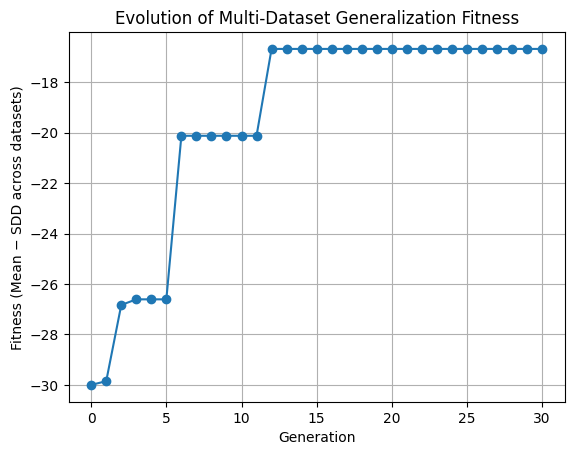

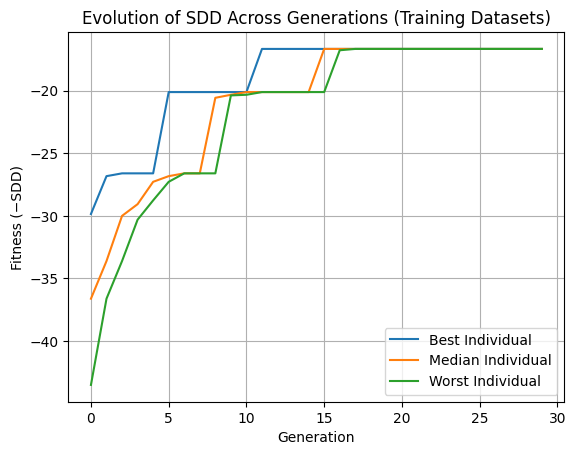

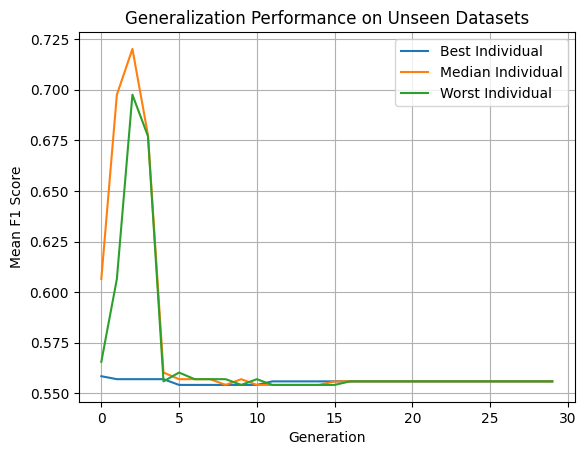

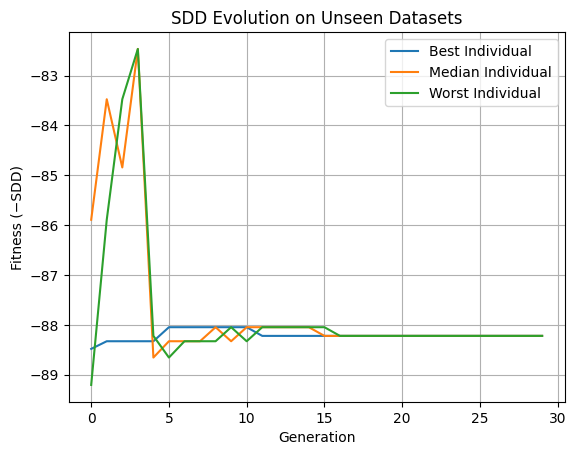

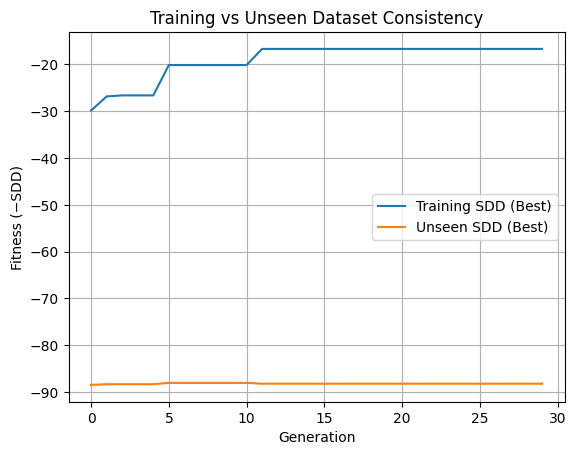

In [10]:
# Graph 1 — Best Fitness Evolution
fig = plt.figure()

plt.plot(history, marker="o")

plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "fitness_evolution.png", dpi=300)



# Graph 2 — Training SDD Evolution
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Best Individual")
plt.plot(fitness_rank_history["median"], label="Median Individual")
plt.plot(fitness_rank_history["worst"], label="Worst Individual")

plt.title("Evolution of SDD Across Generations (Training Datasets)")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_sdd.png", dpi=300)



# Graph 3 — Generalization F1
fig = plt.figure()

plt.plot(generalization_history["best"], label="Best Individual")
plt.plot(generalization_history["median"], label="Median Individual")
plt.plot(generalization_history["worst"], label="Worst Individual")

plt.title("Generalization Performance on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Mean F1 Score")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "generalization_f1.png", dpi=300)



# Graph 4 — Unseen Dataset SDD
fig = plt.figure()

plt.plot(generalization_sdd_history["best"], label="Best Individual")
plt.plot(generalization_sdd_history["median"], label="Median Individual")
plt.plot(generalization_sdd_history["worst"], label="Worst Individual")

plt.title("SDD Evolution on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)

#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "unseen_sdd.png", dpi=300)



# Graph 5 — Training vs Unseen SDD
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Training SDD (Best)")
plt.plot(generalization_sdd_history["best"], label="Unseen SDD (Best)")

plt.title("Training vs Unseen Dataset Consistency")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_vs_unseen_sdd.png", dpi=300)

plt.show()